# Сеть по комбинациям признаков (Airline Passenger Satisfaction)

1. Загрузка `train.csv`, разбиение на `train` / `test`.
2. **Бинаризация** признаков и отбор `D_SEL` признаков для полного перебора.
3. «Потолок» качества для **всех** 2^D − 1 сочетаний (групповая кросс-проверка), правило сокращения k*.
4. Выбор лучших **K** признаков (K = k* или задаётся вручную) — это число входов сети.
5. Свёртка обучающей выборки в комбинации (n, n₁, vF).
6. Сеть K-H-1 (tanh), вариант Б; входы — масштабированные значения признаков.
7. Проверка на тесте.
8. Прогноз для `test.csv` → `submission.csv` (Id и вероятность True).

In [21]:
import sys, os, json, time, itertools, subprocess, shutil
import numpy as np, pandas as pd
from scipy.optimize import linprog
import matplotlib.pyplot as plt

CSV = "train.csv"          # путь к CSV (разделитель ",")
TEST_CSV = None           # если тест лежит в отдельном файле - укажите путь; иначе тест выделяется из CSV случайно
TEST_FRAC = 0.3; SPLIT_SEED = 42
OUT = "out"           # папка для результатов
os.makedirs(OUT, exist_ok=True)

TARGET = "satisfaction"
DROP = ["id"]             # служебные столбцы, не являющиеся признаками
YMAP = {"true": 1, "1": 1, "1.0": 1, "satisfied": 1, "false": 0, "0": 0, "0.0": 0, "neutral or dissatisfied": 0}

D_SEL = 15                # сколько бинарных признаков оставить для полного перебора (перебирается 2^D_SEL - 1 сочетаний)
NFOLD = 5; DELTA = 0.01

K_FORCE = None            # число входов сети K; None - взять k* (правило сокращения), либо задать вручную, например 7
HIDDEN = None             # число скрытых нейронов H; None - H = K
SOFT = True              # False: метка комбинации = vF (вариант Б); True: метка = доля n1/n (вероятности получатся менее "резкими")
PRED_CSV = "test.csv"     # файл для прогноза (как train, но без столбца satisfaction)
ID_COL = "id"

## 1. Данные
Исходные признаки смешанные: возраст, дальность и задержки — числа; оценки сервиса — шкала 0–5; пол, тип клиента, тип поездки и класс — категории. Целевой признак `satisfaction` приводится к 0/1. Строки с пропусками удаляются. Если `TEST_CSV` не задан, тест выделяется из `CSV` случайно с сохранением доли классов (`TEST_FRAC`, `SPLIT_SEED`).

In [2]:
def prep(path):
    d = pd.read_csv(path, sep=",")
    d.columns = d.columns.str.strip()
    d = d.drop(columns=[c for c in d.columns if c in DROP or c.startswith("Unnamed")])
    n0 = len(d); d = d.dropna().reset_index(drop=True)
    if len(d) < n0: print(f"{path}: удалено строк с пропусками: {n0 - len(d)}")
    y = d[TARGET].astype(str).str.strip().str.lower().map(YMAP)
    assert y.notna().all(), f"неизвестные значения целевого признака: {sorted(d[TARGET].astype(str).unique())}"
    d[TARGET] = y.astype(int)
    return d

if TEST_CSV:
    tr_raw, te_raw = prep(CSV), prep(TEST_CSV)
else:
    full = prep(CSV); rng = np.random.default_rng(SPLIT_SEED); te_idx = []
    for c in (0, 1):
        ix = np.where(full[TARGET].values == c)[0]; te_idx.append(rng.choice(ix, int(round(TEST_FRAC * len(ix))), replace=False))
    is_te = np.zeros(len(full), bool); is_te[np.concatenate(te_idx)] = True
    tr_raw, te_raw = full[~is_te].reset_index(drop=True), full[is_te].reset_index(drop=True)
raw_cols = [c for c in tr_raw.columns if c != TARGET]
ytr = tr_raw[TARGET].values.astype(np.int64); yte = te_raw[TARGET].values.astype(np.int64)
yall = np.r_[ytr, yte]; N = len(ytr)
print(f"train {N}, test {len(yte)}, всего {len(yall)}; исходных признаков {len(raw_cols)}; доля класса 1: {yall.mean():.3f}")

train.csv: удалено строк с пропусками: 292
train 489540, test 209803, всего 699343; исходных признаков 22; доля класса 1: 0.444


## 2. Бинаризация и отбор признаков
Метод работает с двоичными признаками, поэтому каждый признак превращается в 0/1 **по обучающей части** (тест не используется):

* числовой признак и оценки 0–5 → правило `x > t`; порог `t` — тот, при котором один этот признак даёт лучшую долю верных ответов на `train`;
* категориальный признак с двумя значениями → «значение = да/нет» (если значений больше двух, берётся самое частое против остальных).

Затем остаются `D_SEL` признаков с лучшей одиночной долей верных ответов — их сочетания и перебираются дальше. При `D_SEL = 15` это 32 767 сочетаний; каждый +1 к `D_SEL` удваивает время перебора.

In [3]:
def acc1(b, y):
    """Доля верных ответов правила «преобладающий класс» по одному двоичному признаку b."""
    b = b.astype(bool); n1 = y[b].sum(); n = b.sum(); m1 = y[~b].sum(); m = (~b).sum()
    return (max(n1, n - n1) + max(m1, m - m1)) / len(y)

def best_cut(x, y):
    u = np.unique(x)
    cand = u[:-1] if len(u) <= 12 else np.unique(np.quantile(x, np.linspace(.05, .95, 19)))
    best_t, best_a = None, -1.0
    for t in cand:
        a = acc1(x > t, y)
        if a > best_a: best_t, best_a = t, a
    return best_t

rules = []
for c in raw_cols:
    s = tr_raw[c]
    if pd.api.types.is_numeric_dtype(s):
        t = best_cut(s.values.astype(float), ytr)
        if t is None: continue                                   # константа - признак бесполезен
        rules.append(dict(col=c, kind="cut", t=float(t), name=f"{c} > {t:g}"))
    else:
        vc = s.astype(str).value_counts(); vals = sorted(vc.index)
        pos = vals[-1] if len(vals) == 2 else vc.index[0]
        rules.append(dict(col=c, kind="cat", pos=pos, name=f"{c} = {pos}"))

def binarize(d):
    cols = [(d[r["col"]].values.astype(float) > r["t"]) if r["kind"] == "cut" else (d[r["col"]].astype(str).values == r["pos"]) for r in rules]
    return np.column_stack(cols).astype(np.int64)
Btr, Bte = binarize(tr_raw), binarize(te_raw)

score = np.array([acc1(Btr[:, j], ytr) for j in range(Btr.shape[1])])
keep = np.sort(np.argsort(-score, kind="stable")[:min(D_SEL, len(rules))])
feats = [rules[j]["name"] for j in keep]; D = len(feats)
print(f"всего двоичных признаков {len(rules)}, оставлено D = {D}, перебор {(1 << D) - 1} сочетаний")
if D > 18: print("внимание: при D > 18 перебор будет очень долгим")

всего двоичных признаков 22, оставлено D = 15, перебор 32767 сочетаний


In [4]:
sel = np.zeros(len(rules), bool); sel[keep] = True
pd.DataFrame(dict(признак=[r["name"] for r in rules], одиночная_доля=score.round(4), оставлен=sel)).sort_values("одиночная_доля", ascending=False).reset_index(drop=True)

,признак,одиночная_доля,оставлен
0,Online boarding > 3,0.8056,True
1,Class = Business,0.7767,True
2,Inflight entertainment > 3,0.7166,True
3,Inflight wifi service > 3,0.7029,True
4,Seat comfort > 3,0.6982,True
5,Flight Distance > 1464,0.6978,True
6,Type of Travel = Personal Travel,0.6767,True
7,Leg room service > 3,0.6709,True
8,On-board service > 3,0.6611,True
9,Ease of Online booking > 3,0.6442,True


In [5]:
Xtr = Btr[:, keep]; Xte = Bte[:, keep]; Xall = np.vstack([Xtr, Xte])
pw = 1 << np.arange(D)
key = lambda X: (X * pw).sum(1)                       # комбинация D признаков -> целое число
ktr, kte, kall = key(Xtr), key(Xte), key(Xall)
print(f"различных комбинаций в train: {len(np.unique(ktr))} из {2 ** D}")

различных комбинаций в train: 8842 из 32768


## 3. Потолок качества для всех сочетаний признаков
Для набора признаков лучшая достижимая доля верных ответов — доля объектов в преобладающем классе своей комбинации: **P = (1/m)·Σ max(n₁, n − n₁)**. Оценка — групповая кросс-проверка по 5 блокам внутри `train`: одинаковые комбинации целиком попадают в один блок. Тест при отборе не используется. Время перебора растёт как 2^D.

In [6]:
Uk, inv_u = np.unique(ktr, return_inverse=True)       # различные комбинации в обучающей части
nu = np.bincount(inv_u).astype(float); ou = np.bincount(inv_u, weights=ytr)
order = np.argsort(-nu, kind="stable"); fold = np.zeros(len(Uk), int); load = np.zeros(NFOLD)
for i in order:                                       # группы (одинаковые комбинации) целиком в один блок
    k = int(np.argmin(load)); fold[i] = k; load[k] += nu[i]
nuk = [nu * (fold != k) for k in range(NFOLD)]; ouk = [ou * (fold != k) for k in range(NFOLD)]
idxk = [np.where(fold == k)[0] for k in range(NFOLD)]
dflt = [bool(ouk[k].sum() > nuk[k].sum() - ouk[k].sum()) for k in range(NFOLD)]

t0 = time.time(); ceil = np.zeros(1 << D)
for mask in range(1, 1 << D):
    _, inv = np.unique(Uk & mask, return_inverse=True); G = inv.max() + 1; corr = 0.0
    for k in range(NFOLD):
        n = np.bincount(inv, weights=nuk[k], minlength=G); o = np.bincount(inv, weights=ouk[k], minlength=G)
        pred = np.where(n > 0, o > n - o, dflt[k]); ix = idxk[k]
        corr += np.where(pred[inv[ix]], ou[ix], nu[ix] - ou[ix]).sum()
    ceil[mask] = corr / N
print(f"перебрано {(1 << D) - 1} сочетаний за {time.time() - t0:.0f} с")
pc = np.array([bin(m).count("1") for m in range(1 << D)])

перебрано 32767 сочетаний за 22 с


### Лучшее сочетание для каждого k и правило сокращения
`lookup` строит таблицу комбинаций (преобладающий класс по всему `train`). Правило сокращения: наименьшее k, при котором потолок отстаёт от максимума не более чем на 0,01.

In [7]:
def lookup(mask):
    """Таблица комбинаций: преобладающий класс по всей обучающей части."""
    uc, inv = np.unique(ktr & mask, return_inverse=True)
    n = np.bincount(inv); o = np.bincount(inv, weights=ytr); vf = (o > n - o).astype(int)
    default = int(ytr.sum() > N - ytr.sum())
    def pred(k):
        c = k & mask; pos = np.clip(np.searchsorted(uc, c), 0, len(uc) - 1); hit = uc[pos] == c
        return np.where(hit, vf[pos], default), hit
    pt, ht = pred(kte); pa, ha = pred(kall)
    return dict(filled=int(len(uc)), unc_test=float(1 - ht.mean()), acc_test=float((pt == yte).mean()), acc_all=float((pa == yall).mean()))
def cv_unc(mask):
    """Доля записей, чья комбинация не встретилась в обучающих блоках кросс-проверки."""
    _, inv = np.unique(Uk & mask, return_inverse=True); G = inv.max() + 1; unc = 0.0
    for k in range(NFOLD):
        n = np.bincount(inv, weights=nuk[k], minlength=G); ix = idxk[k]; unc += nu[ix][n[inv[ix]] == 0].sum()
    return float(unc / N)
names = lambda mask: [feats[i] for i in range(D) if mask >> i & 1]

byk = []
for k in range(1, D + 1):
    ms = np.where(pc == k)[0]; b = ms[np.argmax(ceil[ms])]; L = lookup(int(b))
    byk.append(dict(k=k, subsets=int(len(ms)), combos=2 ** k, filled=L["filled"], unc_test=L["unc_test"],
                    ceil_cv=float(ceil[b]), unc_cv=cv_unc(int(b)), ceil_test=L["acc_test"], mask=int(b), feats=names(int(b)),
                    mean=float(ceil[ms].mean()), mn=float(ceil[ms].min())))
best_all = max(r["ceil_cv"] for r in byk)
kstar = next(r["k"] for r in byk if r["ceil_cv"] >= best_all - DELTA)
print("k* =", kstar, byk[kstar - 1]["feats"], byk[kstar - 1]["ceil_cv"], "максимум", best_all)

k* = 7 ['Flight Distance > 1464', 'Inflight wifi service > 3', 'Ease of Online booking > 3', 'Online boarding > 3', 'Seat comfort > 3', 'Inflight entertainment > 3', 'Type of Travel = Personal Travel'] 0.8813151121460964 максимум 0.889520774604731


In [8]:
pd.DataFrame(byk)[['k','subsets','combos','filled','unc_cv','ceil_cv','ceil_test']].round(4)

,k,subsets,combos,filled,unc_cv,ceil_cv,ceil_test
0,1,15,2,2,0.0000,0.8056,0.8066
1,2,105,4,4,0.0000,0.8529,0.8536
2,3,455,8,8,0.0000,0.8602,0.8614
3,4,1365,16,16,0.0000,0.8674,0.8683
4,5,3003,32,32,0.0000,0.8731,0.8739
5,6,5005,64,64,0.0000,0.8766,0.8788
6,7,6435,128,128,0.0000,0.8813,0.8825
7,8,6435,256,250,0.0000,0.8842,0.8871
8,9,5005,512,474,0.0001,0.8881,0.8895
9,10,3003,1024,852,0.0003,0.8891,0.8908


### Рисунок 1 — потолок всех сочетаний

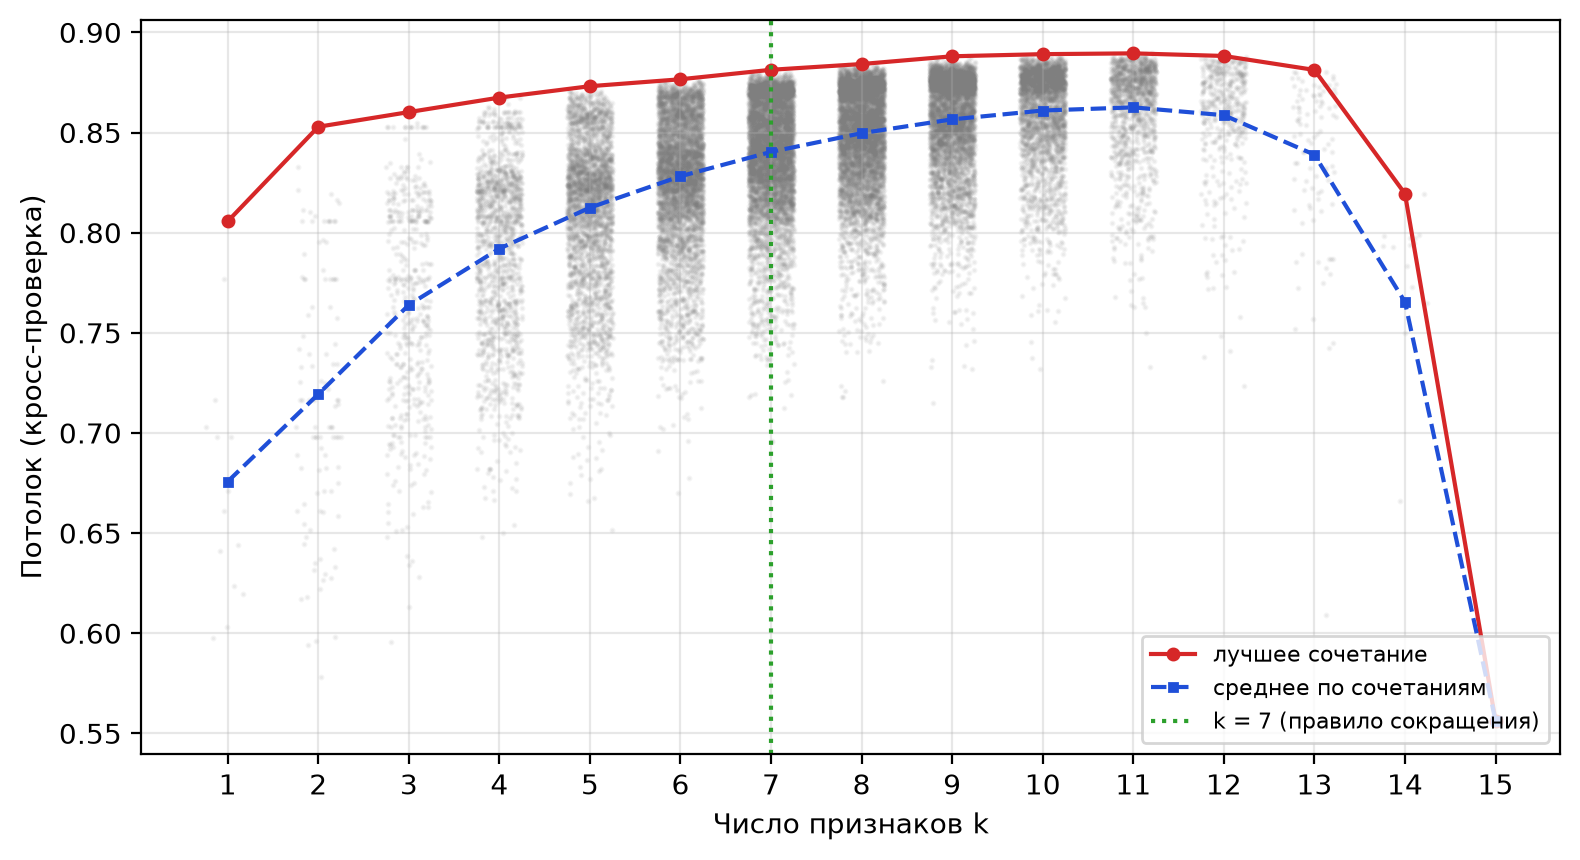

In [9]:
# рисунок 1: потолок всех сочетаний
fig, ax = plt.subplots(figsize=(8, 4.4), dpi=200); r = np.random.default_rng(0)
ax.scatter(pc[1:] + r.uniform(-.25, .25, len(pc) - 1), ceil[1:], s=1.2, alpha=.08, color="#7f7f7f", rasterized=True)
ax.plot([r_["k"] for r_ in byk], [r_["ceil_cv"] for r_ in byk], "o-", color="#d62728", ms=4, label="лучшее сочетание")
ax.plot([r_["k"] for r_ in byk], [r_["mean"] for r_ in byk], "s--", color="#1f4fd8", ms=3, label="среднее по сочетаниям")
ax.axvline(kstar, color="#2ca02c", ls=":", label=f"k = {kstar} (правило сокращения)")
ax.set_xlabel("Число признаков k"); ax.set_ylabel("Потолок (кросс-проверка)"); ax.set_xticks(range(1, D + 1))
ax.grid(alpha=.3); ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig1_ceiling.png")); plt.show()

## 4. Выбор K признаков
`K` — число входов сети. По умолчанию K = k* (наименьшее k, при котором потолок отстаёт от максимума не более чем на 0,01); можно задать вручную через `K_FORCE`. Из всех сочетаний K признаков берётся то, у которого потолок кросс-проверки выше; тест — только для сравнения.

In [10]:
K = K_FORCE or kstar
tm = np.where(pc == K)[0]; oK = tm[np.lexsort((tm, -ceil[tm]))]
top5 = [dict(mask=int(m), feats=names(int(m)), ceil_cv=float(ceil[m]), ceil_test=lookup(int(m))["acc_test"]) for m in oK[:5]]
kmask = int(oK[0]); kidx = [i for i in range(D) if kmask >> i & 1]          # номера выбранных признаков среди feats
best_by_test = max(tm, key=lambda m: lookup(int(m))["acc_test"]); bt = lookup(int(best_by_test))["acc_test"]
cor = [abs(np.corrcoef(Xtr[:, i], ytr)[0, 1]) for i in range(D)]; ctop = np.argsort(-np.array(cor))[:K]
cmask = int(sum(1 << int(i) for i in ctop)); crank = int(np.where(oK == cmask)[0][0]) + 1
corr_info = dict(feats=names(cmask), ceil_cv=float(ceil[cmask]), rank=crank, of=len(tm))
print("K =", K, "| признаки:", names(kmask), ceil[kmask], "| по корреляции:", corr_info)

K = 7 | признаки: ['Flight Distance > 1464', 'Inflight wifi service > 3', 'Ease of Online booking > 3', 'Online boarding > 3', 'Seat comfort > 3', 'Inflight entertainment > 3', 'Type of Travel = Personal Travel'] 0.8813151121460964 | по корреляции: {'feats': ['Flight Distance > 1464', 'Inflight wifi service > 3', 'Online boarding > 3', 'Seat comfort > 3', 'Inflight entertainment > 3', 'Type of Travel = Personal Travel', 'Class = Business'], 'ceil_cv': 0.8796972668219144, 'rank': 7, 'of': 6435}


In [11]:
pd.DataFrame(top5)

,mask,feats,ceil_cv,ceil_test
0,8430,"[Flight Distance > 1464, Inflight wifi service...",0.881315,0.882518
1,24934,"[Flight Distance > 1464, Inflight wifi service...",0.880798,0.881722
2,24750,"[Flight Distance > 1464, Inflight wifi service...",0.880353,0.883105
3,24812,"[Inflight wifi service > 3, Ease of Online boo...",0.880122,0.882919
4,24940,"[Inflight wifi service > 3, Ease of Online boo...",0.880020,0.881937


## 5. Свёртка обучающей выборки в комбинации
Каждый объект получает код — набор из K двоичных значений (−1/+1). Для каждой из 2^K комбинаций: `n` — число объектов, `n1` — число с целевым классом 1, `vF = +1`, если таких больше половины, иначе `−1`. Проверяется, разделяется ли vF одной гиперплоскостью (линейное программирование).

In [12]:
pw_k = 1 << np.arange(K)
code = lambda X: (X[:, kidx] * pw_k).sum(1)                     # код комбинации K признаков: 0 .. 2^K - 1
ctr = code(Xtr)
n_all = np.bincount(ctr, minlength=2 ** K); n1_all = np.bincount(ctr, weights=ytr, minlength=2 ** K)
combos = np.array([[(c >> j & 1) * 2 - 1 for j in range(K)] for c in range(2 ** K)])     # {0,1} -> {-1,+1}
rows = []
for c in range(2 ** K):
    n = int(n_all[c]); n1 = int(n1_all[c])
    rows.append(dict(x=combos[c].tolist(), n=n, n1=n1, share=(n1 / n if n else None), vF=(1 if n1 > n - n1 else -1) if n else 0))
nz = [r for r in rows if r["n"] > 0]
print("комбинаций с данными:", len(nz), "из", 2 ** K)
Aeq = -np.array([[*r["x"], 1] for r in nz]) * np.array([r["vF"] for r in nz])[:, None]
lp = linprog(np.zeros(K + 1), A_ub=Aeq, b_ub=-np.ones(len(nz)), bounds=[(None, None)] * (K + 1), method="highs")
separable = bool(lp.success); print("vF разделяется одной плоскостью:", separable)

комбинаций с данными: 128 из 128
vF разделяется одной плоскостью: False


In [13]:
pd.DataFrame(rows)

,x,n,n1,share,vF
0,"[-1, -1, -1, -1, -1, -1, -1]",51262,4740,0.092466,-1
1,"[1, -1, -1, -1, -1, -1, -1]",12258,1559,0.127182,-1
2,"[-1, 1, -1, -1, -1, -1, -1]",692,204,0.294798,-1
3,"[1, 1, -1, -1, -1, -1, -1]",134,40,0.298507,-1
4,"[-1, -1, 1, -1, -1, -1, -1]",11410,947,0.082997,-1
...,...,...,...,...,...
123,"[1, 1, -1, 1, 1, 1, 1]",22,3,0.136364,-1
124,"[-1, -1, 1, 1, 1, 1, 1]",846,53,0.062648,-1
125,"[1, -1, 1, 1, 1, 1, 1]",68,5,0.073529,-1
126,"[-1, 1, 1, 1, 1, 1, 1]",7175,2620,0.365157,-1


## 6. Сеть K-H-1 (tanh), вариант Б
Обучается только вариант Б: одна строка = одна комбинация, метка — vF. Перебор 48 наборов параметров × 3 начальных состояния (Adam на NumPy); критерий — доля объектов, для которых ответ сети совпал с vF их комбинации.

**Входы сети — масштабированные значения выбранных признаков, а не 0/1:**
* числовой признак (возраст, дальность, задержки, оценки) → `(x − t) / S`, обрезается до [−1, 1], где `t` — порог из бинаризации, `S` — 99-й перцентиль `|x − t|` на `train`. Знак совпадает с двоичным признаком, а величина сохраняет информацию о разбросе;
* текстовый признак → `+1` / `−1` (значение «да» / «нет»);
* вход строки-комбинации — среднее этих значений по объектам комбинации. Пропуски в числах заполняются медианой `train`.

In [14]:
krules = [rules[keep[i]] for i in kidx]                          # правила бинаризации выбранных K признаков
for r in krules:
    if r["kind"] == "cut":
        x = tr_raw[r["col"]].values.astype(float); a = np.abs(x - r["t"]); S = float(np.percentile(a, 99))
        r["S"] = S if S > 0 else max(float(a.max()), 1.0); r["med"] = float(np.median(x))

def encode(d):
    """Исходные данные -> масштабированные входы сети, форма (строк, K)."""
    cols = []
    for r in krules:
        if r["kind"] == "cut":
            x = pd.to_numeric(d[r["col"]], errors="coerce").fillna(r["med"]).values.astype(float)
            cols.append(np.clip((x - r["t"]) / r["S"], -1, 1))
        else:
            cols.append(np.where(d[r["col"]].astype(str).values == r["pos"], 1.0, -1.0))
    return np.column_stack(cols)

Ztr = encode(tr_raw)
Xc = np.array([Ztr[ctr == c].mean(0) for c in range(2 ** K) if n_all[c] > 0])      # вход комбинации = среднее по её объектам
nc = np.array([r["n"] for r in nz], float); vfc = np.array([r["vF"] for r in nz])
yc = np.array([r["share"] for r in nz]) if SOFT else (vfc + 1) / 2

H = HIDDEN or K
def init(seed):
    g = np.random.default_rng(seed); return [g.normal(0, .5, (H, K)), np.zeros(H), g.normal(0, .5, (1, H)), np.zeros(1)]
def fwd(P, X):
    h = np.tanh(X @ P[0].T + P[1]); z = h @ P[2].T + P[3]; return h, z.ravel()
sig = lambda z: 1 / (1 + np.exp(-z))
def train(X, y, w, eta, lam, epochs, seed):
    P = init(seed); M = [np.zeros_like(p) for p in P]; V = [np.zeros_like(p) for p in P]; sw = w.sum()
    for t in range(1, epochs + 1):
        h, z = fwd(P, X); dz2 = ((sig(z) - y) * w / sw)[:, None]
        dh = dz2 @ P[2]; dz1 = dh * (1 - h ** 2)
        G = [dz1.T @ X + lam * P[0], dz1.sum(0), dz2.T @ h + lam * P[2], dz2.sum(0)]
        for i in range(4):
            M[i] = .9 * M[i] + .1 * G[i]; V[i] = .999 * V[i] + .001 * G[i] ** 2
            P[i] = P[i] - eta * (M[i] / (1 - .9 ** t)) / (np.sqrt(V[i] / (1 - .999 ** t)) + 1e-8)
    h, z = fwd(P, X); p = np.clip(sig(z), 1e-12, 1 - 1e-12)
    return P, float(-(w * (y * np.log(p) + (1 - y) * np.log(1 - p))).sum() / sw)

grid = list(itertools.product([0.01, 0.05, 0.1, 0.2], [0, 1e-4, 1e-3, 1e-2], [500, 1000, 2000]))
best = None; w1 = np.ones(len(nz))
for eta, lam, ep in grid:
    for seed in range(3):
        P, loss = train(Xc, yc, w1, eta, lam, ep, seed)
        match = float((((fwd(P, Xc)[1] >= 0) == (vfc == 1)).astype(float) @ nc) / nc.sum())   # совпадение с vF, взвешено по числу объектов
        cand = (-match, loss, ep, eta, lam, seed)
        if best is None or cand < best[0]: best = (cand, P)
(nm, loss, ep, eta, lam, seed), Pf = best
info = dict(K=K, H=H, rows=len(nz), eta=eta, lam=lam, epochs=ep, seed=seed, match=-nm, loss=loss)
print(f"сеть {K}-{H}-1:", info)

сеть 7-7-1: {'K': 7, 'H': 7, 'rows': 128, 'eta': 0.2, 'lam': 0, 'epochs': 2000, 'seed': 1, 'match': 1.0, 'loss': 8.714798207890003e-06}


In [15]:
pd.DataFrame([info]).T

,0
K,7.000000
H,7.000000
rows,128.000000
eta,0.200000
lam,0.000000
epochs,2000.000000
seed,1.000000
match,1.000000
loss,0.000009


In [16]:
pd.DataFrame([dict(w=Pf[0][j].round(3).tolist(), b=float(Pf[1][j]), v=float(Pf[2][0, j])) for j in range(H)])   # нейроны скрытого слоя; смещение выхода: Pf[3]

,w,b,v
0,"[-9.124, -5.279, -0.996, 0.765, -0.082, 2.764,...",-1.172442,7.799682
1,"[4.793, 9.588, -5.207, 4.168, 2.235, 0.453, -3...",-1.522023,6.885472
2,"[0.276, 7.799, -6.135, -4.248, -0.739, 0.435, ...",0.524494,-5.621520
3,"[-0.888, 7.456, 4.297, -1.663, -1.46, 0.883, 0.1]",-3.492145,8.932185
4,"[1.742, -1.083, 1.748, -7.307, -2.805, -0.057,...",4.375025,-9.150202
5,"[9.448, 4.093, -1.955, 3.412, -2.098, 1.502, -...",-2.078110,7.967578
6,"[1.495, -2.478, -0.654, -0.725, -1.389, -4.427...",1.993731,-5.183135


## 7. Проверка на тесте
Тест — часть `train.csv`, не участвовавшая в обучении. Порог 0,5.

In [17]:
def auc(y, p):
    r = pd.Series(p).rank().values; n1 = y.sum(); n0 = len(y) - n1
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
proba = lambda Z: sig(fwd(Pf, Z)[1])
p_tr, p_te = proba(Ztr), proba(encode(te_raw))
print(f"train: доля верных {((p_tr >= .5) == ytr).mean():.4f}, AUC {auc(ytr, p_tr):.4f}")
print(f"test : доля верных {((p_te >= .5) == yte).mean():.4f}, AUC {auc(yte, p_te):.4f}, постоянный ответ {max(yte.mean(), 1 - yte.mean()):.4f}")

train: доля верных 0.8598, AUC 0.9035
test : доля верных 0.8608, AUC 0.9039, постоянный ответ 0.5564


## 8. Прогноз для test.csv
Файл читается теми же правилами (без удаления строк), входы масштабируются параметрами, найденными по `train`. На выходе `submission.csv`: `Id` из `test.csv` и вероятность `True` (выход сети после сигмоиды).

In [22]:
pr = pd.read_csv(PRED_CSV, sep=","); pr.columns = pr.columns.str.strip()
miss = [r["col"] for r in krules if r["col"] not in pr.columns]; assert not miss and ID_COL in pr.columns, f"в {PRED_CSV} нет столбцов: {miss + ([] if ID_COL in pr.columns else [ID_COL])}"
sub = pd.DataFrame({ID_COL: pr[ID_COL].values, TARGET: proba(encode(pr))})
sub.to_csv(os.path.join(OUT, "submission.csv"), index=False)
print(f"{len(sub)} строк, Id {sub[ID_COL].min()}..{sub[ID_COL].max()}, средняя вероятность {sub[TARGET].mean():.3f} -> {os.path.join(OUT, 'submission.csv')}")
sub.head()

299844 строк, Id 699635..999478, средняя вероятность 0.448 -> out/submission.csv


,id,satisfaction
0,699635,1.000000e+00
1,699636,1.000000e+00
2,699637,1.000000e+00
3,699638,3.241936e-10
4,699639,1.741024e-17
